# Lab 6: The Deutsch-Jozsa Algorithm - An Exponential Quantum Leap

Welcome to Lab 6! In the previous lab, we took our first step into quantum algorithms with the Deutsch algorithm. We saw how a single quantum query could solve a problem that required two classical queries, giving us our first taste of quantum speedup. While impressive, that was just a warm-up.

Now, we will scale up this concept to its more powerful and impressive generalization: the **Deutsch-Jozsa algorithm**. This algorithm tackles a similar problem but for functions that operate on an input of *n* bits instead of just one. We are given a function `f(x)` that takes an n-bit string and returns a single bit (`0` or `1`). We are promised that the function is either **constant** (it returns the same value for all 2<sup>n</sup> possible inputs) or **balanced** (it returns `0` for exactly half of the inputs and `1` for the other half).

Classically, determining the nature of this function could be a monumental task. In the worst-case scenario, you would need to check up to (2<sup>n</sup>/2) + 1 inputs to be absolutely certain. For even a moderate number of qubits, this becomes classically intractable. The Deutsch-Jozsa algorithm, however, showcases one of the most dramatic separations between quantum and classical computation. It can determine if the function is constant or balanced with **one single evaluation** of the function, regardless of how large `n` is. This represents an *exponential speedup* over the best possible classical approach.

In this lab, we will:
*   Implement the Deutsch-Jozsa algorithm, the multi-qubit extension of the Deutsch algorithm.
*   Construct quantum oracles for both `constant` functions (which always return `0` or `1`) and `balanced` functions.
*   Build the full algorithm using helper functions to create the oracles and the main circuit structure for an arbitrary number of qubits `n`.
*   Run the algorithm on the **`qasm_simulator`** for various oracles and scale the input size to demonstrate the algorithm's power.
*   Verify the deterministic outcome: a measurement of the all-zero state (`00...0`) indicates a constant function, while any other result proves the function is balanced.
*   Witness a clear and stunning example of exponential quantum speedup, a cornerstone of quantum computing's potential.

Prepare to see how quantum parallelism can be harnessed to solve a complex global property problem with an efficiency that is simply impossible in the classical world.

In [1]:
%pip install qiskit qiskit-aer matplotlib
%pip install qiskit pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 29.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 61.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 73.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit-aer]


In [2]:
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator, Aer
from qiskit.visualization import plot_histogram
import matplotlib
from math import pi, sqrt # pi = 3.14 and square root operation
from qiskit.visualization import plot_state_city # Density Matrix plot
from qiskit.visualization import plot_state_qsphere # used for multi qubit visualisation
from qiskit.visualization import plot_bloch_multivector # Plotting the Bloch Sphere for Single Qubits
from qiskit.visualization import plot_histogram # 2D Histogram Plotting
import numpy as np # Numerical Python Library

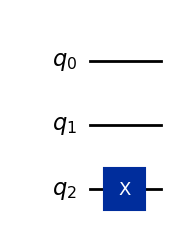

In [3]:
# set the length of the n-bit input register string.
n = 2

const_oracle = QuantumCircuit(n+1)

output = np.random.randint(2) # Randomly generates 0 and 1 (Random Flips)
if output == 1:
    const_oracle.x(n)

const_oracle.draw('mpl')

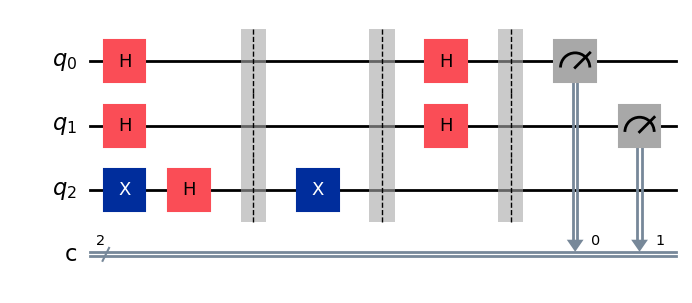

In [4]:
dj_circuit = QuantumCircuit(n+1, n)

# Apply H-gates
for qubit in range(n):
    dj_circuit.h(qubit)

# Put qubit in state |->
dj_circuit.x(n)
dj_circuit.h(n)
dj_circuit.barrier()

# Add oracle
dj_circuit.compose(const_oracle, inplace=True)
dj_circuit.barrier()

# Repeat H-gates
for qubit in range(n):
    dj_circuit.h(qubit)
dj_circuit.barrier()

# Measure
for i in range(n):
    dj_circuit.measure(i, i)

# Display circuit
dj_circuit.draw('mpl')


Total counts are: {'00': 1000}


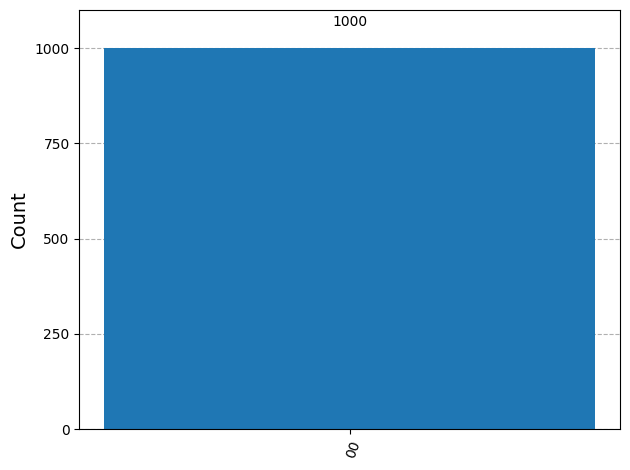

In [5]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(dj_circuit, backend)


# Execute the circuit on the qasm simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(dj_circuit)
print("\nTotal counts are:",counts)

# Plot a histogram
plot_histogram(counts)

As expected for the Deutsch-Jozsa Algorithm, we get 00 as the measurement output which proves that the oracle chosen is indeed constant function.


## Constant Oracle - General Function


In [6]:
def dj_oracle_const(n):
    # We need to make a QuantumCircuit object to return
    # This circuit has n+1 qubits: the size of the input,
    # plus one output qubit
    oracle_qc = QuantumCircuit(n+1)

    # First decide what the fixed output of the oracle will be
    # (either always 0 or always 1)
    output = np.random.randint(2)
    if output == 1:
        oracle_qc.x(n)

    oracle_gate_const = oracle_qc.to_gate()
    oracle_gate_const.name = "Oracle Constant" # To show when we display the circuit
    return oracle_gate_const


In [7]:
def dj_algorithm(dj_oracle_const,n):
    dj_circuit = QuantumCircuit(n+1, n)
    # Set up the output qubit:
    dj_circuit.x(n)
    dj_circuit.h(n)
    # And set up the input register:
    for qubit in range(n):
        dj_circuit.h(qubit)
    # Let's append the oracle gate to our circuit:
    dj_circuit.append(dj_oracle_const, range(n+1))
    # Finally, perform the H-gates again and measure:
    for qubit in range(n):
        dj_circuit.h(qubit)

    for i in range(n):
        dj_circuit.measure(i, i)

    return dj_circuit


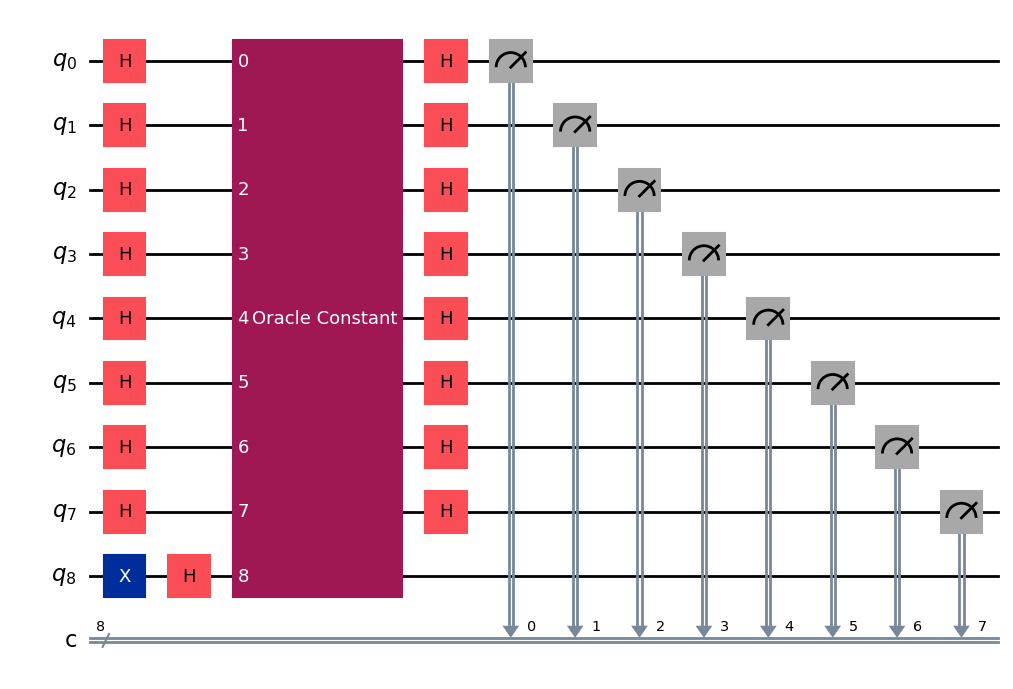

In [8]:
n = 8
oracle_gate_const = dj_oracle_const(n)
dj_circuit = dj_algorithm(oracle_gate_const, n)
dj_circuit.draw('mpl')


Total counts are: {'00000000': 1000}


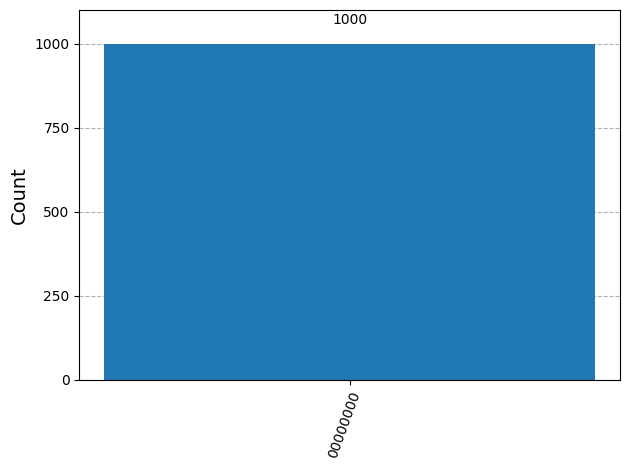

In [9]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(dj_circuit, backend)

# Execute the circuit on the qasm simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(dj_circuit)
print("\nTotal counts are:",counts)

# Plot a histogram
plot_histogram(counts)

## Balanced Oracle
If the measurement of the input registers result is not the zero state |00...0>, then the function is balanced. On the other hand if we measure the state |00...0> then the function is constant.

In [10]:
# set the length of the n-bit input string.
n = 2

### For Inputs |00>
Inputs are the states q0 and q1 which correspond to the first register and q2 corresponds to the output register. The oracle circuit is shown below.

/usr/local/lib/python3.13/dist-packages/qiskit/visualization/circuit/matplotlib.py:273: UserWarning: Style JSON file 'iqx.json' not found in any of these locations: /usr/local/lib/python3.13/dist-packages/qiskit/visualization/circuit/styles/iqx.json, iqx.json. Will use default style.
  self._style, def_font_ratio = load_style(


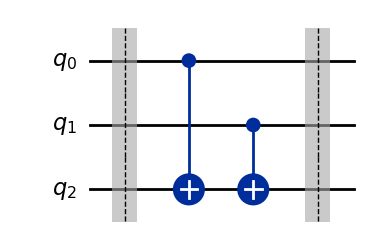

In [11]:
balanced_oracle = QuantumCircuit(n+1)
b_str = "00"

# Place X-gates
for qubit in range(len(b_str)):
    if b_str[qubit] == '1':
        balanced_oracle.x(qubit)

# Use barrier as divider
balanced_oracle.barrier()

# Controlled-NOT gates
for qubit in range(n):
    balanced_oracle.cx(qubit, n)

balanced_oracle.barrier()

# Place X-gates
for qubit in range(len(b_str)):
    if b_str[qubit] == '1':
        balanced_oracle.x(qubit)

# Show oracle
balanced_oracle.draw('mpl', style='iqx')

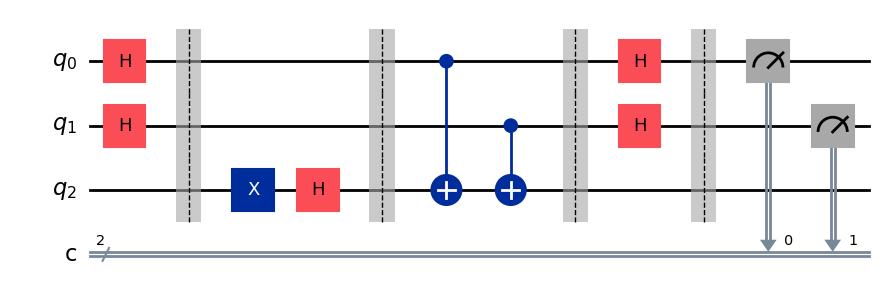

In [12]:
# The Deutsch Jozsa  Full Quantum Circuit
dj_circuit = QuantumCircuit(n+1, n)

# Apply H-gates
for qubit in range(n):
    dj_circuit.h(qubit)
dj_circuit.barrier()

# Put qubit in state |->
dj_circuit.x(n)
dj_circuit.h(n)

# Add oracle
dj_circuit.compose(balanced_oracle, inplace=True)

# Repeat H-gates
for qubit in range(n):
    dj_circuit.h(qubit)
dj_circuit.barrier()

# Measure
for i in range(n):
    dj_circuit.measure(i, i)

# Display circuit
dj_circuit.draw('mpl', style='iqx')


Total counts are: {'11': 1000}


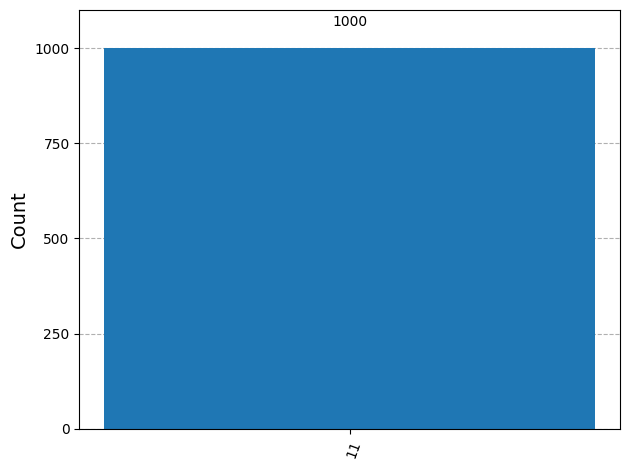

In [13]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(dj_circuit, backend)

# Execute the circuit on the qasm simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(dj_circuit)
print("\nTotal counts are:",counts)

# Plot a histogram
plot_histogram(counts)

## For Inputs |01>
The oracle circuit is shown below.

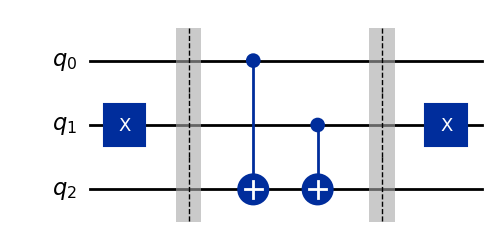

In [14]:
balanced_oracle = QuantumCircuit(n+1)
b_str = "01"

# Place X-gates
for qubit in range(len(b_str)):
    if b_str[qubit] == '1':
        balanced_oracle.x(qubit)

# Use barrier as divider
balanced_oracle.barrier()

# Controlled-NOT gates
for qubit in range(n):
    balanced_oracle.cx(qubit, n)

balanced_oracle.barrier()

# Place X-gates
for qubit in range(len(b_str)):
    if b_str[qubit] == '1':
        balanced_oracle.x(qubit)

# Show oracle
balanced_oracle.draw('mpl')

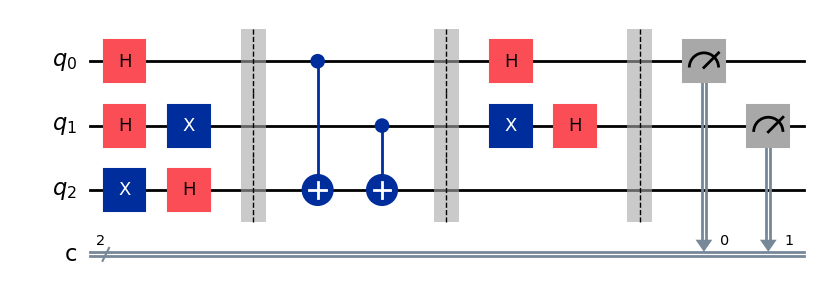

In [15]:
# The Deutsch Jozsa  Full Quantum Circuit
dj_circuit = QuantumCircuit(n+1, n)

# Apply H-gates
for qubit in range(n):
    dj_circuit.h(qubit)

# Put qubit in state |->
dj_circuit.x(n)
dj_circuit.h(n)

# Add oracle
dj_circuit.compose(balanced_oracle, inplace=True)

# Repeat H-gates
for qubit in range(n):
    dj_circuit.h(qubit)
dj_circuit.barrier()

# Measure
for i in range(n):
    dj_circuit.measure(i, i)

# Display circuit
dj_circuit.draw('mpl')


Total counts are: {'11': 1000}


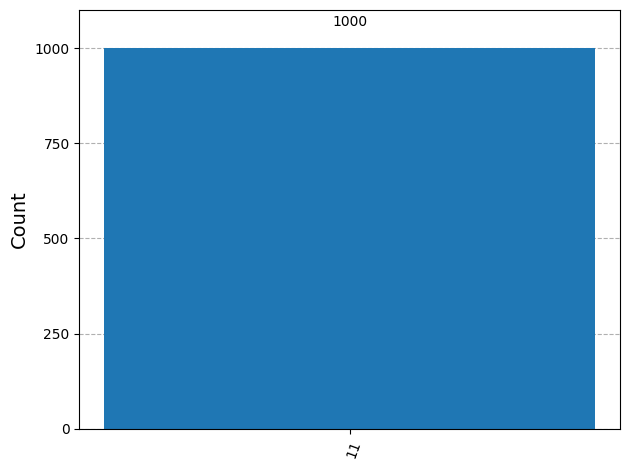

In [16]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(dj_circuit, backend)

# Execute the circuit on the qasm simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(dj_circuit)
print("\nTotal counts are:",counts)

# Plot a histogram
plot_histogram(counts)

## For Inputs |10>
The oracle circuit is shown below.

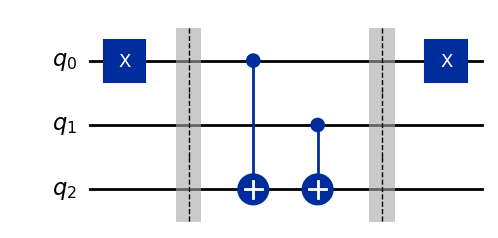

In [17]:
balanced_oracle = QuantumCircuit(n+1)
b_str = "10"

# Place X-gates
for qubit in range(len(b_str)):
    if b_str[qubit] == '1':
        balanced_oracle.x(qubit)

# Use barrier as divider
balanced_oracle.barrier()

# Controlled-NOT gates
for qubit in range(n):
    balanced_oracle.cx(qubit, n)

balanced_oracle.barrier()

# Place X-gates
for qubit in range(len(b_str)):
    if b_str[qubit] == '1':
        balanced_oracle.x(qubit)

# Show oracle
balanced_oracle.draw('mpl')

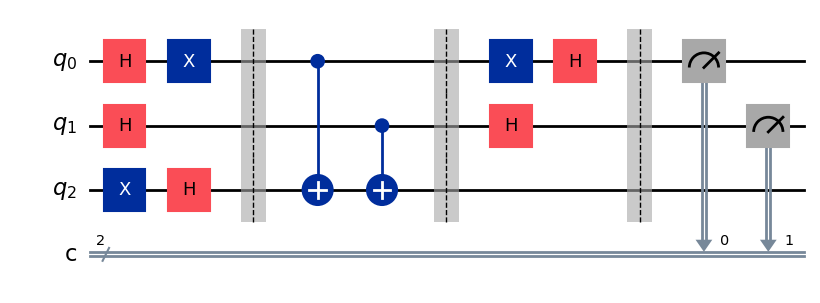

In [18]:
# The Deutsch Jozsa  Full Quantum Circuit
dj_circuit = QuantumCircuit(n+1, n)

# Apply H-gates
for qubit in range(n):
    dj_circuit.h(qubit)

# Put qubit in state |->
dj_circuit.x(n)
dj_circuit.h(n)

# Add oracle
dj_circuit.compose(balanced_oracle, inplace=True)

# Repeat H-gates
for qubit in range(n):
    dj_circuit.h(qubit)
dj_circuit.barrier()

# Measure
for i in range(n):
    dj_circuit.measure(i, i)

# Display circuit
dj_circuit.draw('mpl')


Total counts are: {'11': 1000}


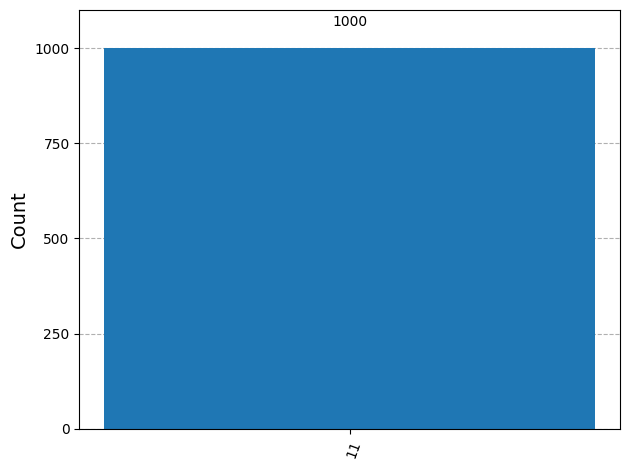

In [19]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(dj_circuit, backend)

# Execute the circuit on the qasm simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(dj_circuit)
print("\nTotal counts are:",counts)

# Plot a histogram
plot_histogram(counts)

## For Inputs |11>
The Oracle circuit is shown below

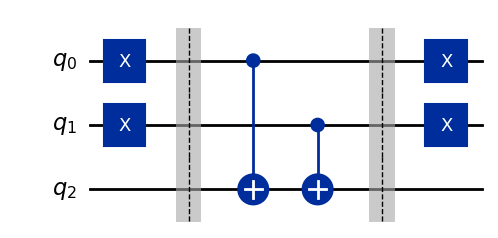

In [20]:
balanced_oracle = QuantumCircuit(n+1)
b_str = "11"

# Place X-gates
for qubit in range(len(b_str)):
    if b_str[qubit] == '1':
        balanced_oracle.x(qubit)

# Use barrier as divider
balanced_oracle.barrier()

# Controlled-NOT gates
for qubit in range(n):
    balanced_oracle.cx(qubit, n)

balanced_oracle.barrier()

# Place X-gates
for qubit in range(len(b_str)):
    if b_str[qubit] == '1':
        balanced_oracle.x(qubit)

# Show oracle
balanced_oracle.draw('mpl')

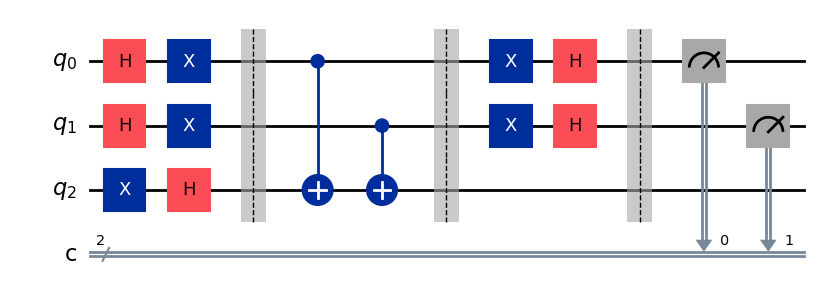

In [21]:
# The Deutsch Jozsa  Full Quantum Circuit
dj_circuit = QuantumCircuit(n+1, n)

# Apply H-gates
for qubit in range(n):
    dj_circuit.h(qubit)

# Put qubit in state |->
dj_circuit.x(n)
dj_circuit.h(n)

# Add oracle
dj_circuit.compose(balanced_oracle, inplace=True)

# Repeat H-gates
for qubit in range(n):
    dj_circuit.h(qubit)
dj_circuit.barrier()

# Measure
for i in range(n):
    dj_circuit.measure(i, i)

# Display circuit
dj_circuit.draw('mpl')


Total counts are: {'11': 1000}


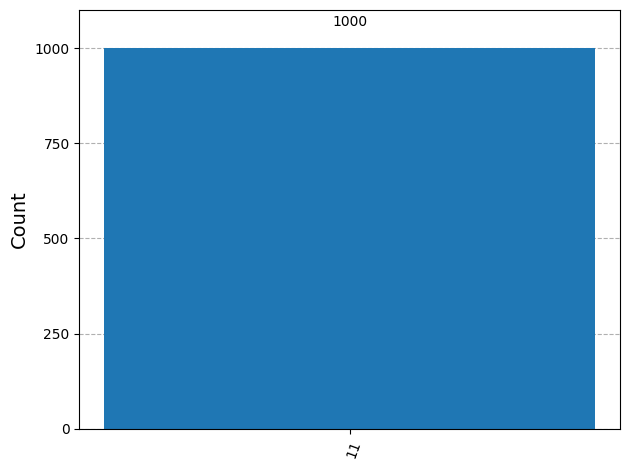

In [22]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(dj_circuit, backend)

# Execute the circuit on the qasm simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(dj_circuit)
print("\nTotal counts are:",counts)

# Plot a histogram
plot_histogram(counts)

As expected for the Deutsch-Jozsa Algorithm, we get 11 as the measurement output for all the inputs |00>, |01>, |10> and |11> which proves that the oracle chosen is indeed balanced function.

## Balanced Oracle - General Function

In [23]:
def dj_oracle_balanced(n):
    # We need to make a QuantumCircuit object to return
    # This circuit has n+1 qubits: the size of the input,
    # plus one output qubit
    oracle_qc = QuantumCircuit(n+1)

    # First generate a random number that tells us which CNOTs to
    # wrap in X-gates:
    b = np.random.randint(1,2**n)

    # Next, format 'b' as a binary string of length 'n', padded with zeros:
    b_str = format(b, '0'+str(n)+'b')

    # Next, we place the first X-gates. Each digit in our binary string
    # corresponds to a qubit, if the digit is 0, we do nothing, if it's 1
    # we apply an X-gate to that qubit:
    for qubit in range(len(b_str)):
        if b_str[qubit] == '1':
            oracle_qc.x(qubit)

    # Do the controlled-NOT gates for each qubit, using the output qubit
    # as the target:
    for qubit in range(n):
        oracle_qc.cx(qubit, n)

    # Next, place the final X-gates
    for qubit in range(len(b_str)):
        if b_str[qubit] == '1':
            oracle_qc.x(qubit)


    oracle_gate_balanced = oracle_qc.to_gate()
    oracle_gate_balanced.name = "Oracle Balanced" # To show when we display the circuit
    return oracle_gate_balanced

In [24]:
def dj_algorithm(dj_oracle_balanced,n):
    dj_circuit = QuantumCircuit(n+1, n)
    # Set up the output qubit:
    dj_circuit.x(n)
    dj_circuit.h(n)
    # And set up the input register:
    for qubit in range(n):
        dj_circuit.h(qubit)
    # Let's append the oracle gate to our circuit:
    dj_circuit.append(dj_oracle_balanced, range(n+1))
    # Finally, perform the H-gates again and measure:
    for qubit in range(n):
        dj_circuit.h(qubit)

    for i in range(n):
        dj_circuit.measure(i, i)

    return dj_circuit

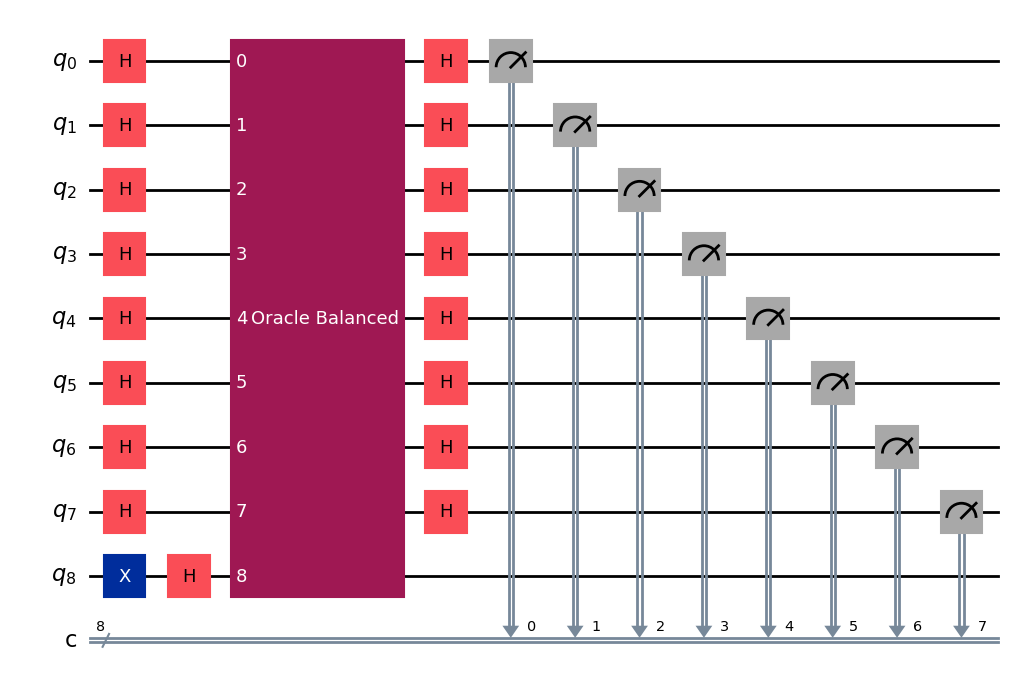

In [25]:
n = 8
oracle_gate_balanced = dj_oracle_balanced(n)
dj_circuit = dj_algorithm(oracle_gate_balanced, n)
dj_circuit.draw('mpl')


Total counts are: {'11111111': 1000}


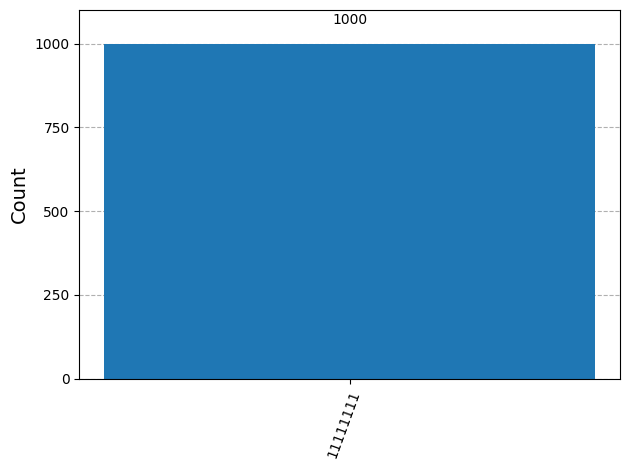

In [26]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(dj_circuit, backend)

# Execute the circuit on the qasm simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(dj_circuit)
print("\nTotal counts are:",counts)

# Plot a histogram
plot_histogram(counts)

## Constant + Balanced Combined - General Function


In [27]:
def dj_oracle(case, n):
    # We need to make a QuantumCircuit object to return
    # This circuit has n+1 qubits: the size of the input,
    # plus one output qubit
    oracle_qc = QuantumCircuit(n+1)

    # First, let's deal with the case in which oracle is balanced
    if case == "balanced":
        # First generate a random number that tells us which CNOTs to
        # wrap in X-gates:
        b = np.random.randint(1,2**n)
        # Next, format 'b' as a binary string of length 'n', padded with zeros:
        b_str = format(b, '0'+str(n)+'b')
        # Next, we place the first X-gates. Each digit in our binary string
        # corresponds to a qubit, if the digit is 0, we do nothing, if it's 1
        # we apply an X-gate to that qubit:
        for qubit in range(len(b_str)):
            if b_str[qubit] == '1':
                oracle_qc.x(qubit)
        # Do the controlled-NOT gates for each qubit, using the output qubit
        # as the target:
        for qubit in range(n):
            oracle_qc.cx(qubit, n)
        # Next, place the final X-gates
        for qubit in range(len(b_str)):
            if b_str[qubit] == '1':
                oracle_qc.x(qubit)

    # Case in which oracle is constant
    if case == "constant":
        # First decide what the fixed output of the oracle will be
        # (either always 0 or always 1)
        output = np.random.randint(2)
        if output == 1:
            oracle_qc.x(n)

    oracle_gate = oracle_qc.to_gate()
    oracle_gate.name = "Oracle" # To show when we display the circuit
    return oracle_gate


In [28]:
def dj_algorithm(oracle, n):
    dj_circuit = QuantumCircuit(n+1, n)
    # Set up the output qubit:
    dj_circuit.x(n)
    dj_circuit.h(n)
    # And set up the input register:
    for qubit in range(n):
        dj_circuit.h(qubit)
    # Let's append the oracle gate to our circuit:
    dj_circuit.append(oracle, range(n+1))
    # Finally, perform the H-gates again and measure:
    for qubit in range(n):
        dj_circuit.h(qubit)

    for i in range(n):
        dj_circuit.measure(i, i)

    return dj_circuit


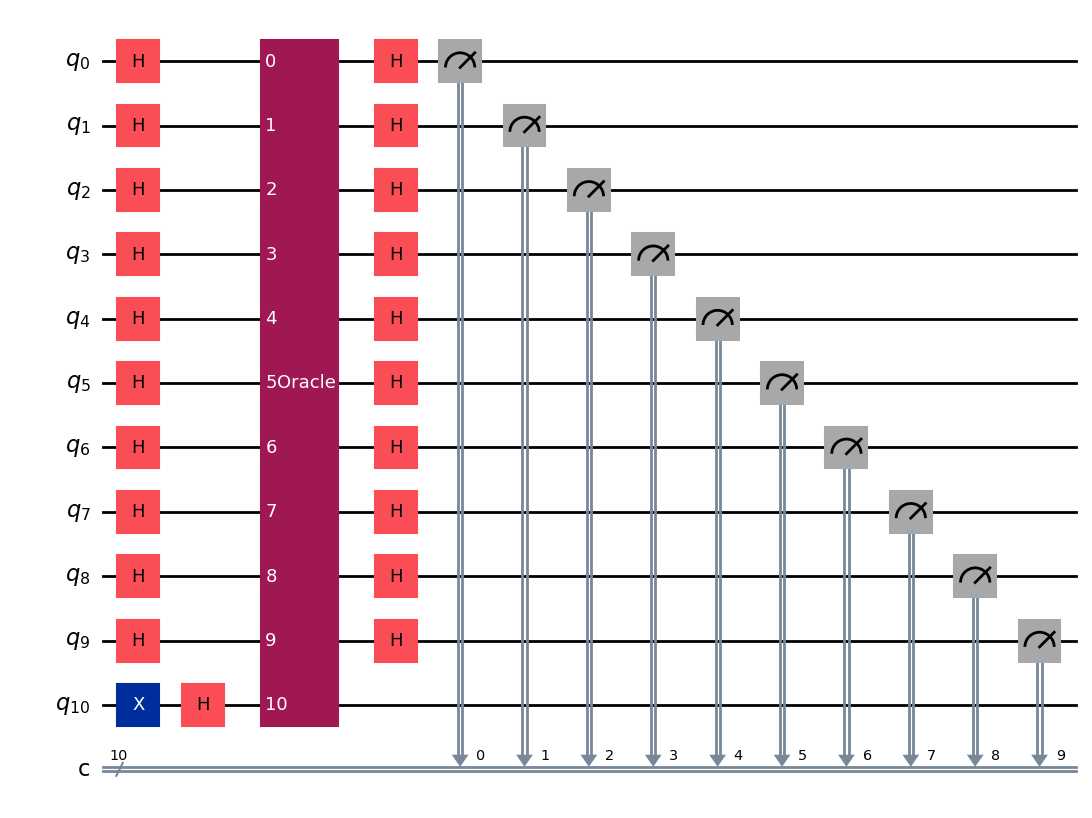

In [29]:
n = 10
oracle_gate = dj_oracle('balanced', n)
dj_circuit = dj_algorithm(oracle_gate, n)
dj_circuit.draw('mpl')


Total counts are: {'1111111111': 1000}


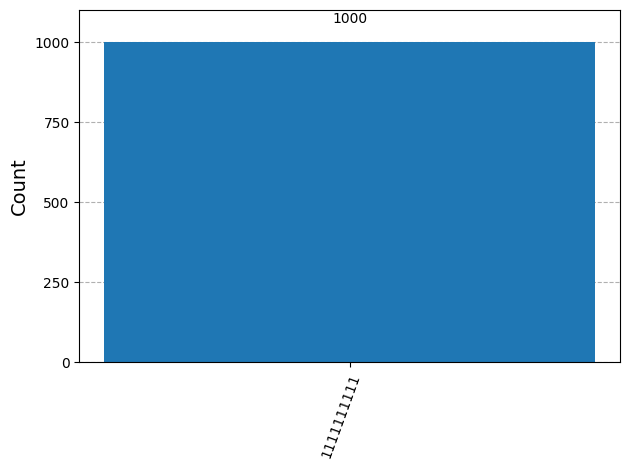

In [30]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(dj_circuit, backend)

# Execute the circuit on the qasm simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(dj_circuit)
print("\nTotal counts are:",counts)

# Plot a histogram
plot_histogram(counts)